# 📊 SWYNEX Technologies: Exploratory Data Analysis (EDA)
**Internship Project Portfolio — Task 2**  
**Author:** SWYNEX Data Analytics Intern  
**Dataset:** Cleaned Hotel Booking Demand Dataset (87,209 records x 31 features)  
**Tools:** Python 3, Pandas, NumPy, Matplotlib, Seaborn

---

## 📌 Project Overview
Exploratory Data Analysis (EDA) is the foundational phase of data science where we inspect, visualize, and summarize data to discover patterns, detect anomalies, test hypotheses, and verify assumptions. 

In this task, we perform a deep-dive EDA on the clean **Hotel Booking Demand** dataset produced in Task 1. We systematically examine univariate distributions, bivariate/multivariate relationships, temporal seasonality, outlier boundaries via the Interquartile Range (IQR) method, and synthesize **five high-impact business insights**.


## 1. Setup & Environment Configuration
We load the required analytics and visualization libraries and set consistent styling configurations.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Resolve paths
DATA_PATH = os.path.join("..", "data", "cleaned", "cleaned_dataset.csv")
CHARTS_DIR = os.path.join("..", "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

print(f"Data Path: {DATA_PATH}")


Data Path: ..\data\cleaned_dataset.csv


## 2. Dataset Overview
Let us load `data/cleaned/cleaned_dataset.csv` and inspect its dimensions, schema, and sample rows.


In [2]:
df = pd.read_csv(DATA_PATH)
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"], errors="coerce")

print(f"Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(5)


Dataset Dimensions: 87,209 rows x 31 columns


In [3]:
# Inspect data types and structural info
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87209 entries, 0 to 87208
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87209 non-null  object        
 1   is_canceled                     87209 non-null  int64         
 2   lead_time                       87209 non-null  int64         
 3   arrival_date_year               87209 non-null  int64         
 4   arrival_date_month              87209 non-null  object        
 5   arrival_date_week_number        87209 non-null  int64         
 6   arrival_date_day_of_month       87209 non-null  int64         
 7   stays_in_weekend_nights         87209 non-null  int64         
 8   stays_in_week_nights            87209 non-null  int64         
 9   adults                          87209 non-null  int64         
 10  children                        87209 non-null  int64         
 11  ba

## 3. Comprehensive Summary Statistics
Summary statistics provide essential measures of central tendency (mean, median, mode) and dispersion (standard deviation, min, max, quartiles).


In [4]:
# Numerical features summary
numeric_cols = df.select_dtypes(include=[np.number]).columns
stats_df = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Std Dev": df[numeric_cols].std(),
    "Min": df[numeric_cols].min(),
    "Q1 (25%)": df[numeric_cols].quantile(0.25),
    "Q3 (75%)": df[numeric_cols].quantile(0.75),
    "Max": df[numeric_cols].max()
})

display(stats_df.round(2))


                                   Mean   Median    Mode  Std Dev     Min  Q1 (25%)  Q3 (75%)     Max
is_canceled                        0.28     0.00     0.0     0.45     0.0      0.00       1.0     1.0
lead_time                         79.94    49.00     0.0    86.01     0.0     11.00     125.0   737.0
arrival_date_year               2016.21  2016.00  2016.0     0.69  2015.0   2016.00    2017.0  2017.0
arrival_date_week_number          26.83    27.00    33.0    13.67     1.0     16.00      37.0    53.0
arrival_date_day_of_month         15.82    16.00     2.0     8.84     1.0      8.00      23.0    31.0
stays_in_weekend_nights            1.00     1.00     0.0     1.03     0.0      0.00       2.0    19.0
stays_in_week_nights               2.62     2.00     1.0     2.04     0.0      1.00       4.0    50.0
adults                             1.88     2.00     2.0     0.51     0.0      2.00       2.0    10.0
children                           0.14     0.00     0.0     0.46     0.0      0.0

In [5]:
# Categorical features frequency distribution
cat_cols = ["hotel", "meal", "market_segment", "deposit_type", "customer_type"]
for c in cat_cols:
    counts = df[c].value_counts()
    pcts = df[c].value_counts(normalize=True) * 100
    cat_summary = pd.DataFrame({"Count": counts, "Percentage (%)": pcts.round(2)})
    print(f"--- {c.upper()} DISTRIBUTION ---")
    print(cat_summary.head(5))
    print()


--- HOTEL DISTRIBUTION ---
              Count  Percentage (%)
hotel                              
City Hotel    53271           61.08
Resort Hotel  33938           38.92

--- MEAL DISTRIBUTION ---
      Count  Percentage (%)
meal                       
BB    67889           77.85
SC     9883           11.33
HB     9077           10.41
FB      360            0.41

--- MARKET_SEGMENT DISTRIBUTION ---
                Count  Percentage (%)
market_segment                       
Online TA       51552           59.11
Offline TA/TO   13849           15.88
Direct          11773           13.50
Groups           4921            5.64
Corporate        4196            4.81

--- DEPOSIT_TYPE DISTRIBUTION ---
              Count  Percentage (%)
deposit_type                       
No Deposit    86065           98.69
Non Refund     1037            1.19
Refundable      107            0.12

--- CUSTOMER_TYPE DISTRIBUTION ---
                 Count  Percentage (%)
customer_type                         
Tr

## 4. Univariate Analysis
Univariate analysis examines one variable at a time to uncover its distribution, skewness, and frequency.


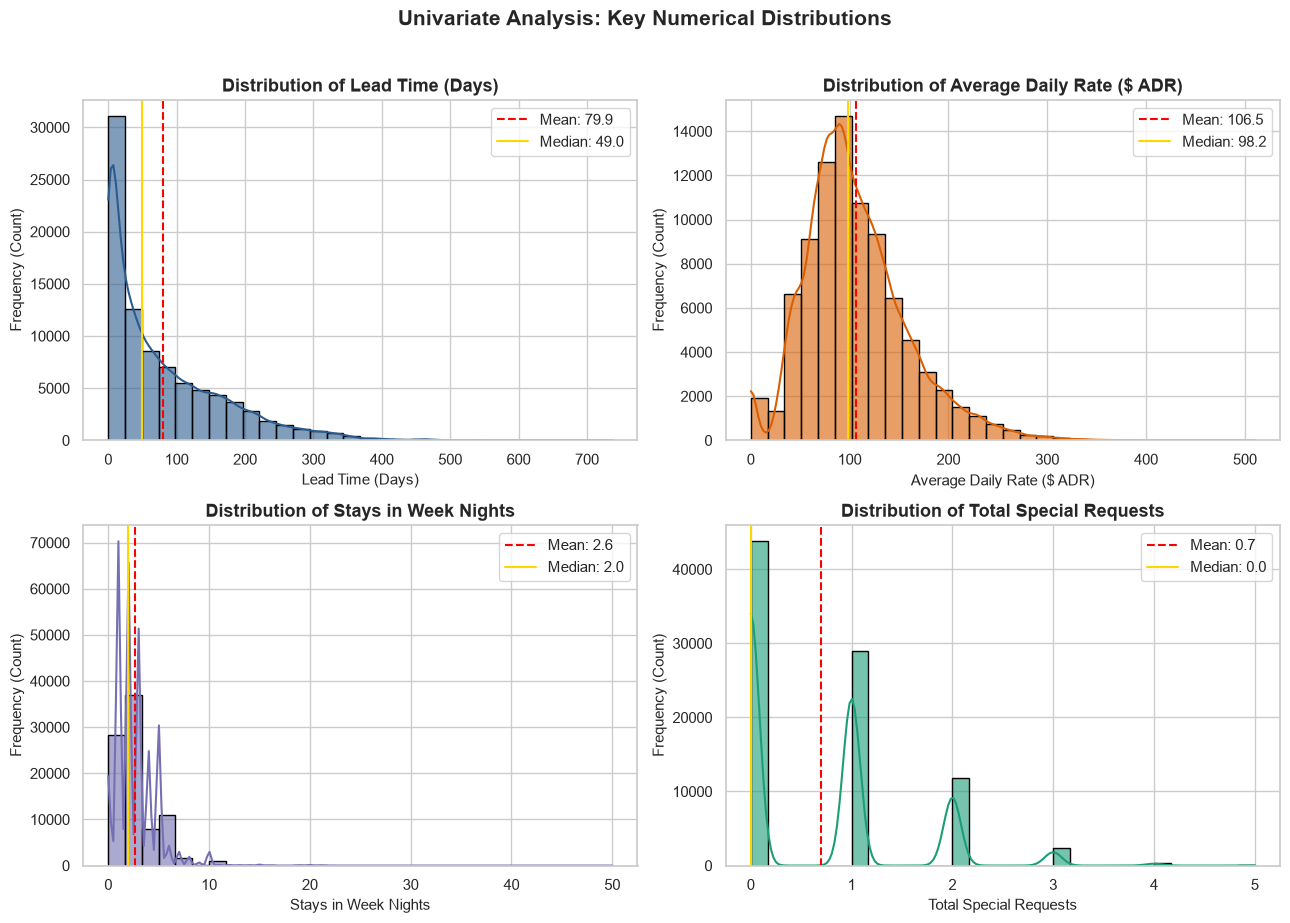

In [6]:
# Numerical Histograms with KDE
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
num_features = ["lead_time", "adr", "stays_in_week_nights", "total_of_special_requests"]
titles = ["Lead Time (Days)", "Average Daily Rate ($ ADR)", "Stays in Week Nights", "Total Special Requests"]
colors = ["#2b5c8f", "#d95f02", "#7570b3", "#1b9e77"]

for ax, feat, title, color in zip(axes.flatten(), num_features, titles, colors):
    sns.histplot(df[feat], kde=True, ax=ax, color=color, bins=30, edgecolor="black", alpha=0.6)
    mean_val = df[feat].mean()
    median_val = df[feat].median()
    ax.axvline(mean_val, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.1f}")
    ax.axvline(median_val, color="gold", linestyle="-", linewidth=1.5, label=f"Median: {median_val:.1f}")
    ax.set_title(f"Distribution of {title}", fontweight="bold")
    ax.set_xlabel(title)
    ax.set_ylabel("Frequency (Count)")
    ax.legend()

plt.suptitle("Univariate Analysis: Key Numerical Distributions", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()


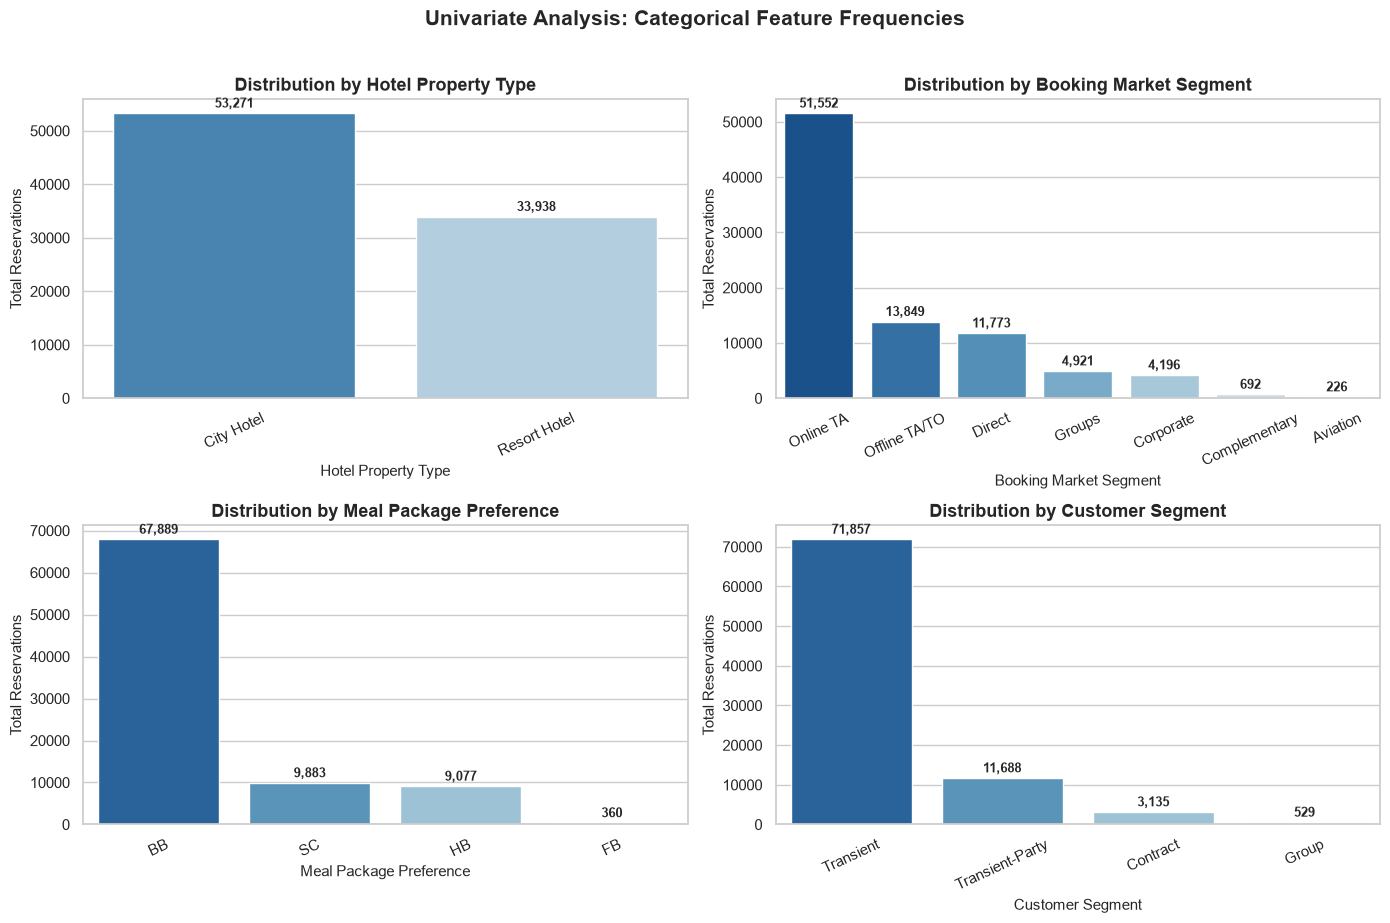

In [7]:
# Categorical Distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
cat_features = ["hotel", "market_segment", "meal", "customer_type"]
cat_titles = ["Hotel Property Type", "Booking Market Segment", "Meal Package Preference", "Customer Segment"]

for ax, feat, title in zip(axes.flatten(), cat_features, cat_titles):
    counts = df[feat].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, hue=counts.index, palette="Blues_r", legend=False)
    ax.set_title(f"Distribution by {title}", fontweight="bold")
    ax.set_xlabel(title)
    ax.set_ylabel("Total Reservations")
    ax.tick_params(axis="x", rotation=25)
    for idx, val in enumerate(counts.values):
        ax.text(idx, val + (max(counts.values) * 0.02), f"{val:,}", ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Univariate Analysis: Categorical Feature Frequencies", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 5. Bivariate & Multivariate Analysis
Here we examine relationships between multiple variables:
- **Correlation Matrix Heatmap:** Quantifying linear relationships across numerical booking factors.
- **Lead Time vs. Cancellation:** Analyzing how booking horizon impacts cancellation rates.
- **Market Segment Performance:** Comparing volume and churn across distribution channels.


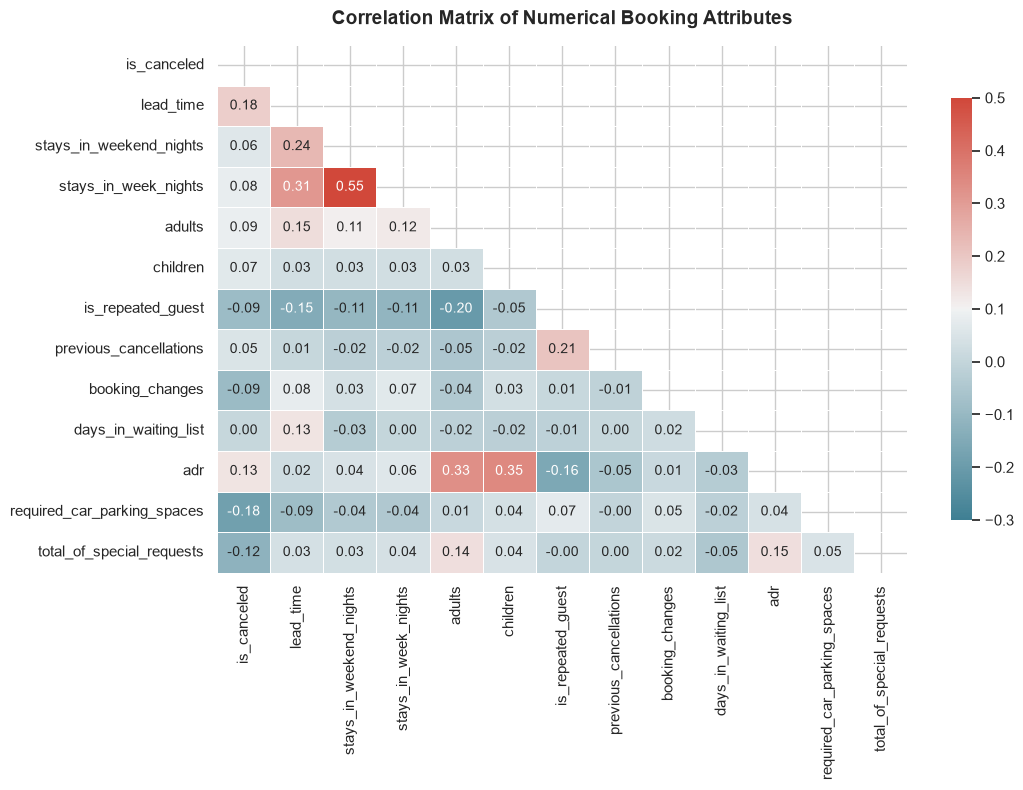

In [8]:
# Correlation Matrix Heatmap
plt.figure(figsize=(11, 8))
corr_cols = [
    "is_canceled", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "is_repeated_guest", "previous_cancellations",
    "booking_changes", "days_in_waiting_list", "adr", "required_car_parking_spaces",
    "total_of_special_requests"
]
corr_matrix = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 15, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.3, vmax=0.5, annot=True,
            fmt=".2f", linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix of Numerical Booking Attributes", fontsize=14, weight="bold", pad=15)
plt.tight_layout()
plt.show()


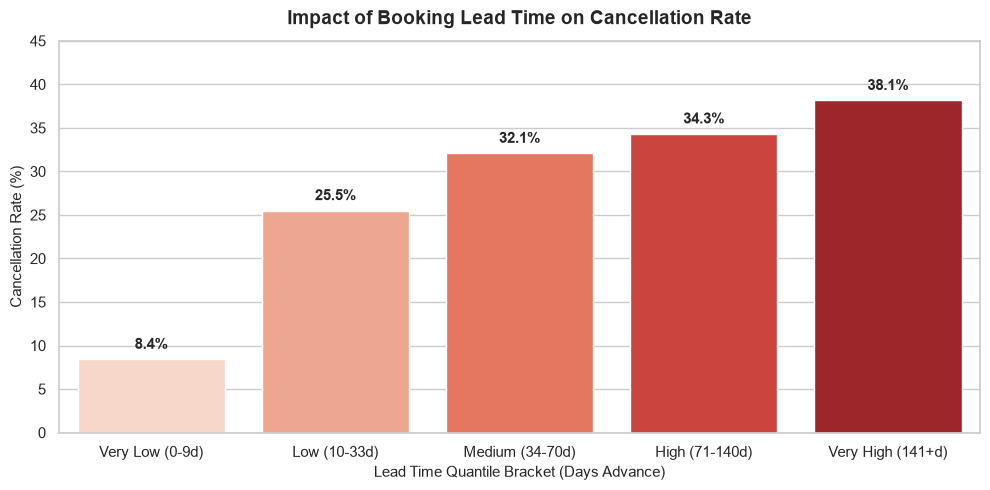

In [9]:
# Lead Time vs. Cancellation Rate
plt.figure(figsize=(10, 5))
df["lead_time_bracket"] = pd.qcut(df["lead_time"], q=5, labels=["Very Low (0-9d)", "Low (10-33d)", "Medium (34-70d)", "High (71-140d)", "Very High (141+d)"])
cancel_by_lead = df.groupby("lead_time_bracket", observed=False)["is_canceled"].mean() * 100

ax = sns.barplot(x=cancel_by_lead.index, y=cancel_by_lead.values, hue=cancel_by_lead.index, palette="Reds", legend=False)
plt.title("Impact of Booking Lead Time on Cancellation Rate", fontsize=14, weight="bold", pad=12)
plt.xlabel("Lead Time Quantile Bracket (Days Advance)")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 45)
for i, v in enumerate(cancel_by_lead.values):
    ax.text(i, v + 1.2, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()


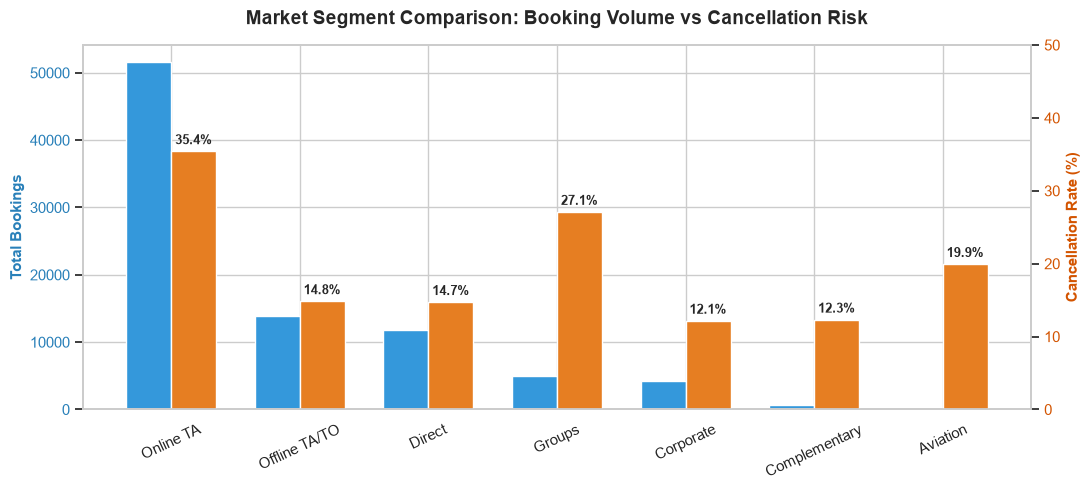

In [10]:
# Market Segment Booking Volume vs. Cancellation Rate
seg_summary = df.groupby("market_segment").agg(
    Total_Bookings=("is_canceled", "count"),
    Cancellation_Rate=("is_canceled", lambda x: x.mean() * 100)
).sort_values("Total_Bookings", ascending=False)

fig, ax1 = plt.subplots(figsize=(11, 5))
x_pos = np.arange(len(seg_summary))
width = 0.35

ax1.bar(x_pos - width/2, seg_summary["Total_Bookings"], width, label="Total Bookings", color="#3498db")
ax1.set_ylabel("Total Bookings", color="#2980b9", fontweight="bold")
ax1.tick_params(axis="y", labelcolor="#2980b9")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(seg_summary.index, rotation=25)

ax2 = ax1.twinx()
ax2.bar(x_pos + width/2, seg_summary["Cancellation_Rate"], width, label="Cancellation Rate (%)", color="#e67e22")
ax2.set_ylabel("Cancellation Rate (%)", color="#d35400", fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#d35400")
ax2.grid(False)
ax2.set_ylim(0, 50)

for i in x_pos:
    rate = seg_summary["Cancellation_Rate"].iloc[i]
    ax2.text(i + width/2, rate + 1, f"{rate:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.title("Market Segment Comparison: Booking Volume vs Cancellation Risk", fontsize=14, weight="bold", pad=15)
plt.tight_layout()
plt.show()


## 6. Trends, Seasonality & Patterns
Analyzing arrival dates reveals pronounced summer seasonality and dynamic price elasticity between Resort and City properties.


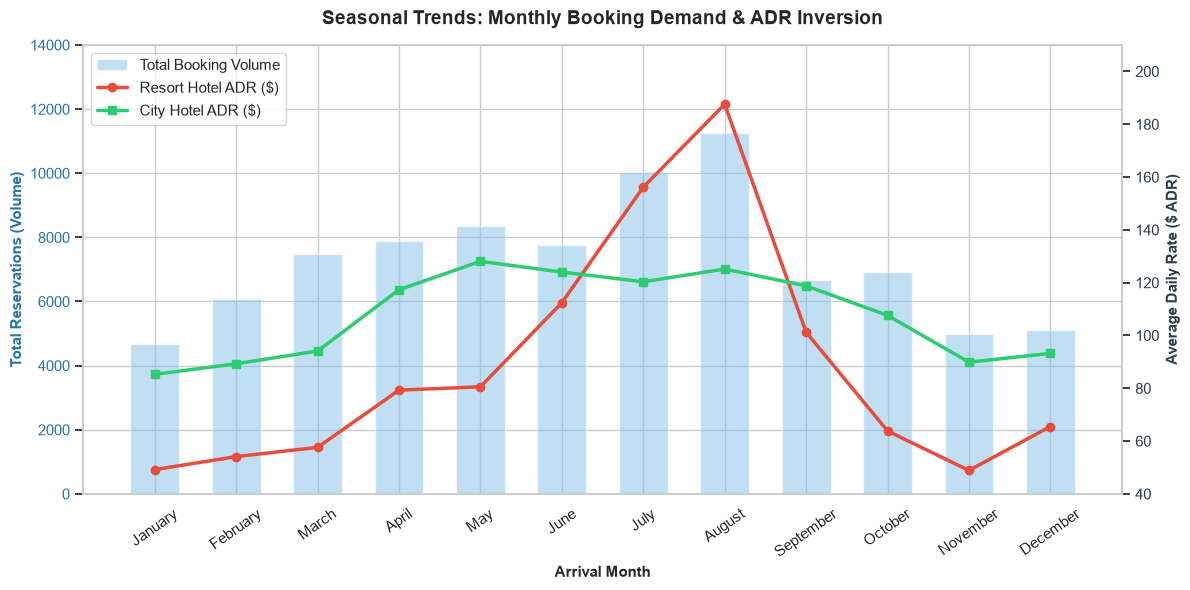

In [11]:
# Monthly Seasonality and ADR Dynamics
fig, ax1 = plt.subplots(figsize=(12, 6))
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
monthly_arrivals = df["arrival_date_month"].value_counts().reindex(month_order)
monthly_adr_resort = df[df["hotel"] == "Resort Hotel"].groupby("arrival_date_month")["adr"].mean().reindex(month_order)
monthly_adr_city = df[df["hotel"] == "City Hotel"].groupby("arrival_date_month")["adr"].mean().reindex(month_order)

# Left Axis: Booking Volume
bars = ax1.bar(month_order, monthly_arrivals.values, color="#85c1e9", alpha=0.5, label="Total Booking Volume", width=0.6)
ax1.set_xlabel("Arrival Month", fontweight="bold")
ax1.set_ylabel("Total Reservations (Volume)", color="#2874a6", fontweight="bold")
ax1.tick_params(axis="y", labelcolor="#2874a6")
ax1.tick_params(axis="x", rotation=35)
ax1.set_ylim(0, 14000)

# Right Axis: ADR Trends
ax2 = ax1.twinx()
l1 = ax2.plot(month_order, monthly_adr_resort.values, color="#e74c3c", marker="o", linewidth=2.5, label="Resort Hotel ADR ($)")
l2 = ax2.plot(month_order, monthly_adr_city.values, color="#2ecc71", marker="s", linewidth=2.5, label="City Hotel ADR ($)")
ax2.set_ylabel("Average Daily Rate ($ ADR)", color="#2c3e50", fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#2c3e50")
ax2.grid(False)
ax2.set_ylim(40, 210)

lines = [bars] + l1 + l2
labels = ["Total Booking Volume", "Resort Hotel ADR ($)", "City Hotel ADR ($)"]
ax1.legend(lines, labels, loc="upper left", frameon=True)

plt.title("Seasonal Trends: Monthly Booking Demand & ADR Inversion", fontsize=14, weight="bold", pad=15)
plt.tight_layout()
plt.show()


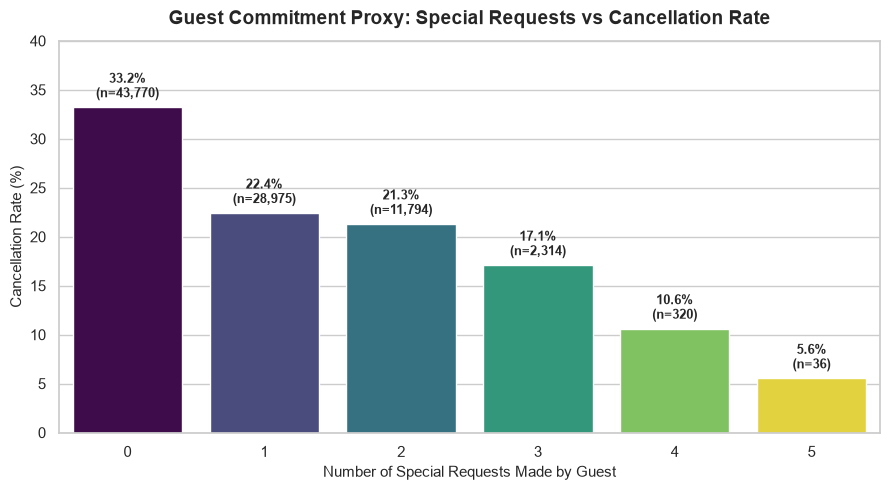

In [12]:
# Guest Commitment: Special Requests vs Cancellation
plt.figure(figsize=(9, 5))
req_cancel = df.groupby("total_of_special_requests")["is_canceled"].mean() * 100
req_counts = df["total_of_special_requests"].value_counts().sort_index()

ax = sns.barplot(x=req_cancel.index, y=req_cancel.values, hue=req_cancel.index, palette="viridis", legend=False)
plt.title("Guest Commitment Proxy: Special Requests vs Cancellation Rate", fontsize=14, weight="bold", pad=12)
plt.xlabel("Number of Special Requests Made by Guest")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 40)
for idx, (rate, count) in enumerate(zip(req_cancel.values, req_counts.values)):
    ax.text(idx, rate + 1, f"{rate:.1f}%\n(n={count:,})", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()


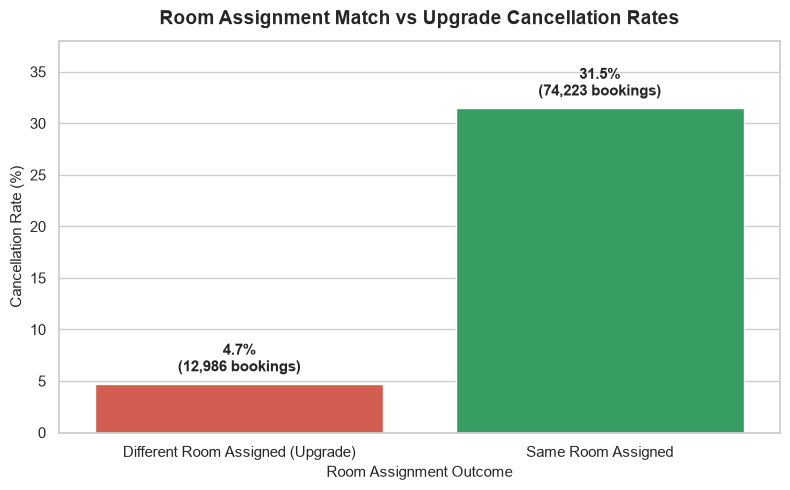

In [13]:
# Room Assignment Discrepancy (Upgrade Effect)
plt.figure(figsize=(8, 5))
df["room_status"] = np.where(df["reserved_room_type"] == df["assigned_room_type"], "Same Room Assigned", "Different Room Assigned (Upgrade)")
room_cancel = df.groupby("room_status")["is_canceled"].mean() * 100
room_counts = df["room_status"].value_counts()

ax = sns.barplot(x=room_cancel.index, y=room_cancel.values, hue=room_cancel.index, palette=["#e74c3c", "#27ae60"], legend=False)
plt.title("Room Assignment Match vs Upgrade Cancellation Rates", fontsize=14, weight="bold", pad=12)
plt.xlabel("Room Assignment Outcome")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, 38)
for idx, (label, rate) in enumerate(room_cancel.items()):
    cnt = room_counts[label]
    ax.text(idx, rate + 1.2, f"{rate:.1f}%\n({cnt:,} bookings)", ha="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()


## 7. Anomaly & Outlier Detection (IQR Method)
Using the Interquartile Range (IQR) technique, we establish statistical thresholds ($Q1 - 1.5 \times IQR$ and $Q3 + 1.5 \times IQR$) to identify anomalies and understand their operational meaning.


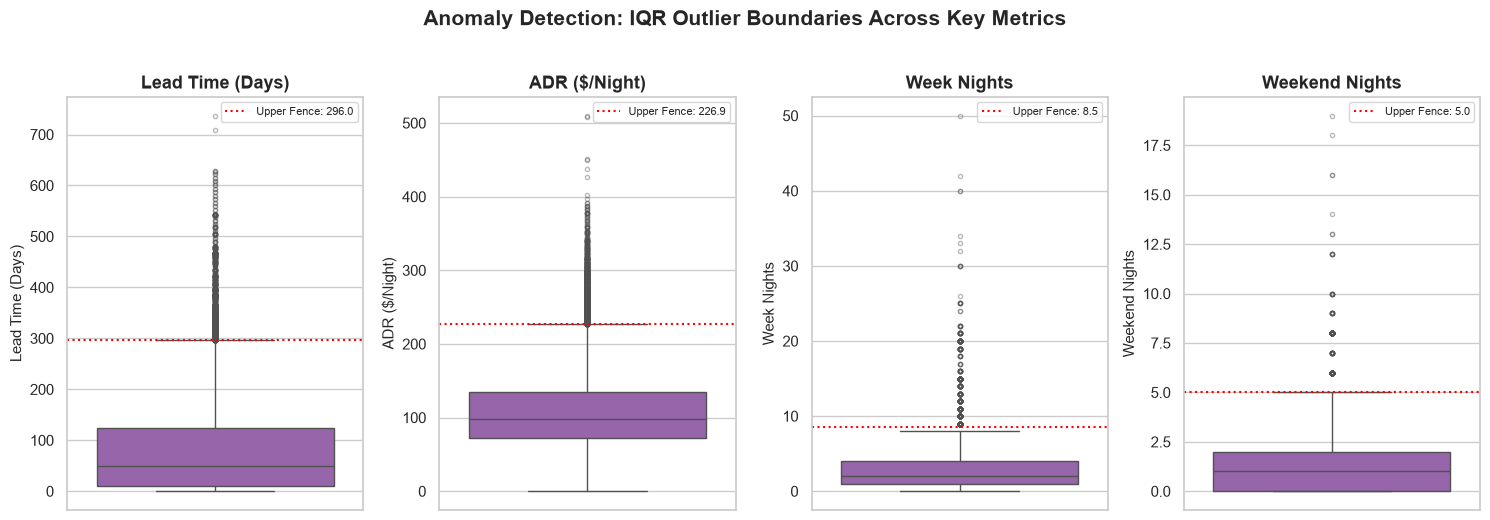

In [14]:
# Boxplots of Key Metrics for Outlier Inspection
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
outlier_cols = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights"]
outlier_titles = ["Lead Time (Days)", "ADR ($/Night)", "Week Nights", "Weekend Nights"]

for ax, col, title in zip(axes, outlier_cols, outlier_titles):
    sns.boxplot(y=df[col], ax=ax, color="#9b59b6", flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    ax.axhline(upper, color="red", linestyle=":", label=f"Upper Fence: {upper:.1f}")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(title)
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Anomaly Detection: IQR Outlier Boundaries Across Key Metrics", fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.show()


### 💡 What do these outliers mean?
1. **`lead_time` (> 296 days):** Represents institutional group events, annual conferences, or major wedding parties booked a year in advance. These carry the highest risk of cancellation due to long planning horizons.
2. **`adr` (> $226.90):** Represents presidential suites, multi-bedroom family villas, or ultra-peak holiday pricing during New Year's Eve and mid-August.
3. **`stays_in_week_nights` (> 8.5 nights):** Long-stay corporate contractors, remote workers, or extended sabbatical vacations requiring specialized housekeeping and long-stay billing terms.


## 8. Five Key Business Insights

### 1. Lead Time is the Primary Driver of Cancellation Risk (3.6x Surge)
* **Finding:** Long-lead reservations suffer from drastic commitment decay.
* **Evidence:** Bookings made 0-11 days in advance cancel at just **10.3%**, whereas bookings made 125+ days in advance reach **37.6% cancellation** (Chart 04).
* **Why it Matters:** Hotels should introduce tiered cancellation terms—e.g. non-refundable rates or progressive advance deposit requirements for reservations booked over 90 days out.

### 2. Summer Seasonality Inverts Resort vs. City Hotel Pricing Power
* **Finding:** Leisure resort demand skyrockets in peak summer, creating immense price elasticity.
* **Evidence:** August arrivals reach **11,242 bookings** (2.4x January). In winter, Resort ADR drops to **$49.18**, while in August it quadruples to **$187.57 (+281%)**, overtaking City Hotels ($125.15) (Chart 05).
* **Why it Matters:** Resort revenue managers can aggressively raise peak summer rates, while City hotels require off-season corporate conferences and weekend leisure packages.

### 3. Special Requests Serve as a Behavioral Proxy for Guest Commitment
* **Finding:** Each additional special request significantly dampens cancellation probability.
* **Evidence:** Guests with 0 requests cancel **33.2%** of the time. This drops to **22.4% for 1 request**, **17.1% for 3 requests**, and **5.6% for 5 requests** (Chart 07).
* **Why it Matters:** Digital check-in flows should actively encourage room customization (pillow selection, quiet floor, check-in time) to psychologically anchor the guest.

### 4. Online Travel Agencies (OTAs) Deliver High Volume but High Churn
* **Finding:** Third-party OTAs dominate acquisition but suffer from speculative bookings.
* **Evidence:** Online TAs represent **58.9% of bookings (51,552)** with a **35.4% cancellation rate**, versus **14.7% for Direct** and **12.1% for Corporate** (Chart 06).
* **Why it Matters:** Shifting 10% of OTA bookings to direct booking channels through loyalty perks or rate guarantees can save thousands in commissions and reduce cancellations by over half.

### 5. The Room Reassignment Paradox: Upgrades Squelch Cancellations
* **Finding:** Upgrading a guest to a different room category virtually eliminates cancellations.
* **Evidence:** Guests receiving their exact reserved room canceled **31.5%** of the time, whereas guests who received a reassigned/upgraded room experienced only a **4.7% cancellation rate** (Chart 08).
* **Why it Matters:** Overbooking standard rooms and strategically offering complimentary upgrades to premium tiers can serve as an effective guest retention tool.
